# Image Visibility Graph

**Important source**: 
- https://core.ac.uk/download/pdf/201006092.pdf.
- *Iacovacci, J., & Lacasa, L. (2019). Visibility graphs for image processing. IEEE transactions on pattern analysis and machine intelligence, 42(4), 974-987.*

%%latex
# Image Visibility Graph (IVG) por parches — Nota de método

## Visión general

El **Image Visibility Graph (IVG)** por parches es un descriptor **local**, **eficiente** e **interpretable** para imágenes en escala de grises.  
La imagen se recorre con parches $k\times k$; en cada parche se evalúan **tests binarios** sobre líneas (filas, columnas y diagonales).  
Los bits resultantes se empaquetan en una **etiqueta** y la imagen completa se resume como un **histograma** de etiquetas (perfil IVG), utilizable como vector de características en tareas de clasificación, regresión o búsqueda.

**Propiedades clave**
- **Eficiencia:** tiempo lineal en el número de píxeles.  
- **Interpretabilidad:** cada bit corresponde a una pauta local concreta (línea visible o no).  
- **Robustez fotométrica:** al basarse en comparaciones $>$ y $<$, es invariante ante transformaciones puntuales estrictamente crecientes (p. ej., cambios globales de brillo/contraste con ganancia positiva).

---

## Notación y definición

Sea una imagen $I \in \mathbb{R}^{H \times W}$. Fijamos un tamaño de parche $k \ge 3$.  
Para cada posición $(i,j)$ generamos el parche $P_{ij} \in \mathbb{R}^{k \times k}$.

En cada parche evaluamos $T$ líneas de longitud $k$:
- $k$ **filas** (horizontales),
- $k$ **columnas** (verticales),
- 2 **diagonales** (principal y secundaria).

Así,
$$
T = 2k + 2.
$$

### Predicado de visibilidad (regla por defecto)

Para una línea $(x_0,\dots,x_{k-1})$ definimos el predicado:
$$
\mathrm{vis}(x_0,\dots,x_{k-1})
\;\equiv\;
(x_1 < x_0)\ \land\ (x_2 > x_1)\ \land\ \cdots\ \land\ (x_{k-1} > x_{k-2}).
$$

- Para $k=3$ se reduce a $x_0 > x_1 < x_2$.  
- La regla puede **personalizarse** (ver *Extensiones*): desigualdades no estrictas, tolerancia $\varepsilon$, otras pautas (monótona, pico, valle, etc.).

Cada línea produce un bit $V(t) \in \{0,1\}$. Apilamos los bits en el orden:
1. $k$ filas (de arriba a abajo),
2. $k$ columnas (de izquierda a derecha),
3. diagonal principal,
4. diagonal secundaria.

Esto define el **vector de bits** $\mathbf{V} \in \{0,1\}^{T}$ del parche.

### Codificación de etiqueta

Codificamos $\mathbf{V}$ como:
$$
L \;=\; 1 + \sum_{t=1}^{T} V(t)\, 2^{\,T-t},
\qquad L \in \{1,\dots,2^{T}\}.
$$
Cada parche queda representado por su etiqueta $L$.

### Perfil de la imagen (histograma)

Sea $L_{ij}$ la etiqueta del parche anclado en $(i,j)$. Definimos el **perfil**:
$$
Z_\ell \;=\; \sum_{i,j} \mathbf{1}\!\left[L_{ij}=\ell\right],
\qquad \ell=1,\dots,2^{T}.
$$

En práctica usamos como **vector de características** la versión normalizada y transformada:
$$
\mathbf{h} \;=\;
\sqrt{\frac{\mathbf{Z}}{\sum_{\ell=1}^{2^{T}} Z_\ell}}
\quad\text{(normalización L1 + transformación de Hellinger)}.
$$

---

## Algoritmo (resumen)

1. **Extracción de parches** $k\times k$ (p. ej., con *strides* para evitar copias).  
2. **Evaluación de líneas**: $k$ filas, $k$ columnas y 2 diagonales con el predicado de visibilidad.  
3. **Empaquetado de bits** $\mathbf{V} \rightarrow L$.  
4. **Acumulación** del histograma global $\mathbf{Z}$.  
5. **Normalización y proyección** para obtener $\mathbf{h}$.

### Pseudocódigo

```text
Input : imagen I, tamaño de parche k ≥ 3
Output: histograma Z de longitud 2^(2k+2)

Z ← vector de ceros de tamaño 2^(2k+2)
para cada parche P = I[i:i+k, j:j+k]:
    V ← bits[1..(2k+2)] ← 0

    # k filas
    para r = 0..k-1:
        x ← P[r, 0..k-1]
        V[r] ← vis(x)

    # k columnas
    para c = 0..k-1:
        x ← P[0..k-1, c]
        V[k + c] ← vis(x)

    # diagonales
    V[2k]   ← vis( diag_principal(P) )
    V[2k+1] ← vis( diag_secundaria(P) )

    # etiqueta
    L ← 1 + Σ_{t=1}^{2k+2} V[t] · 2^(2k+1 - t)
    Z[L] ← Z[L] + 1

return Z


**Predicado por defecto:**

vis(x0,...,x_{k-1}) := (x1 < x0) AND (x2 > x1) AND ... AND (x_{k-1} > x_{k-2})

El resultado de `patch_profile_visibility_vectorized(img, order=k)` son dos salidas:

1. **Z — histograma de etiquetas**  
   Es un vector 1D de longitud $(2^T)+1$, donde $T=2k+2$ es el número total de “tests” ($k$ filas + $k$ columnas + 2 diagonales).  
   El índice $0$ de $Z$ **no se usa** (se deja en 0 para coincidir con el pseudocódigo que numera etiquetas desde 1).  
   Para cada etiqueta $L \in [1, 2^T]$, $Z[L]$ guarda cuántos parches tienen exactamente ese patrón de bits $V(1), \dots, V(T)$.  
   **Ejemplo:** para $k=3$, $T=8$ y hay $2^8 = 256$ etiquetas posibles, así que $\mathrm{len}(Z)=257$.  
   En otras palabras, $Z$ es el **perfil global de visibilidad** de la imagen: cuántas veces aparece cada tipo de patrón en todos los parches $k \times k$.

2. **Lmap — mapa de etiquetas por parche**  
   Es un arreglo 2D de forma $(H-k+1,\, W-k+1)$, donde cada posición $(i,j)$ corresponde al parche $k \times k$ que empieza en `img[i:i+k, j:j+k]`.  
   Cada celda contiene el entero $L \in [1, 2^T]$ que codifica el patrón de bits para ese parche.  
   Esto es útil si quieres ver **dónde** ocurren ciertos patrones en la imagen o hacer **análisis local**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

In [2]:
#Para tener en cuenta: https://www.researchsquare.com/article/rs-3409328/v1

In [3]:
ts=np.random.randint(1,30,20)

In [4]:
ts

array([25, 10,  8,  9, 11, 24,  3, 19, 11,  3,  8, 16, 11, 16, 27, 19, 21,
       23, 25, 23])

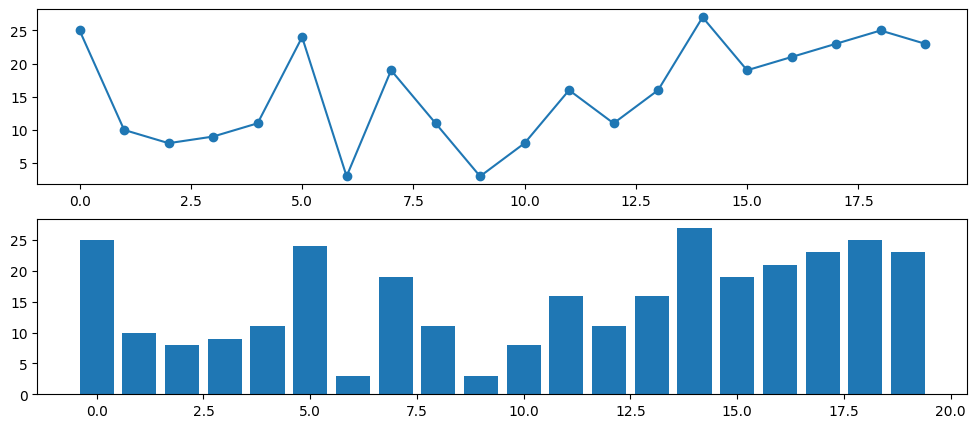

In [5]:
plt.figure(figsize=(12,5))
plt.subplot(211)
plt.plot(ts,marker="o")
plt.subplot(212)
plt.bar(range(len(ts)),ts)
plt.show()

## Clasical Time series Visibility graph algorith

**Important source**:
- https://www.pnas.org/doi/abs/10.1073/pnas.0709247105.
- *Lacasa, L., Luque, B., Ballesteros, F., Luque, J., & Nuno, J. C. (2008). From time series to complex networks: The visibility graph. Proceedings of the National Academy of Sciences, 105(13), 4972-4975.*

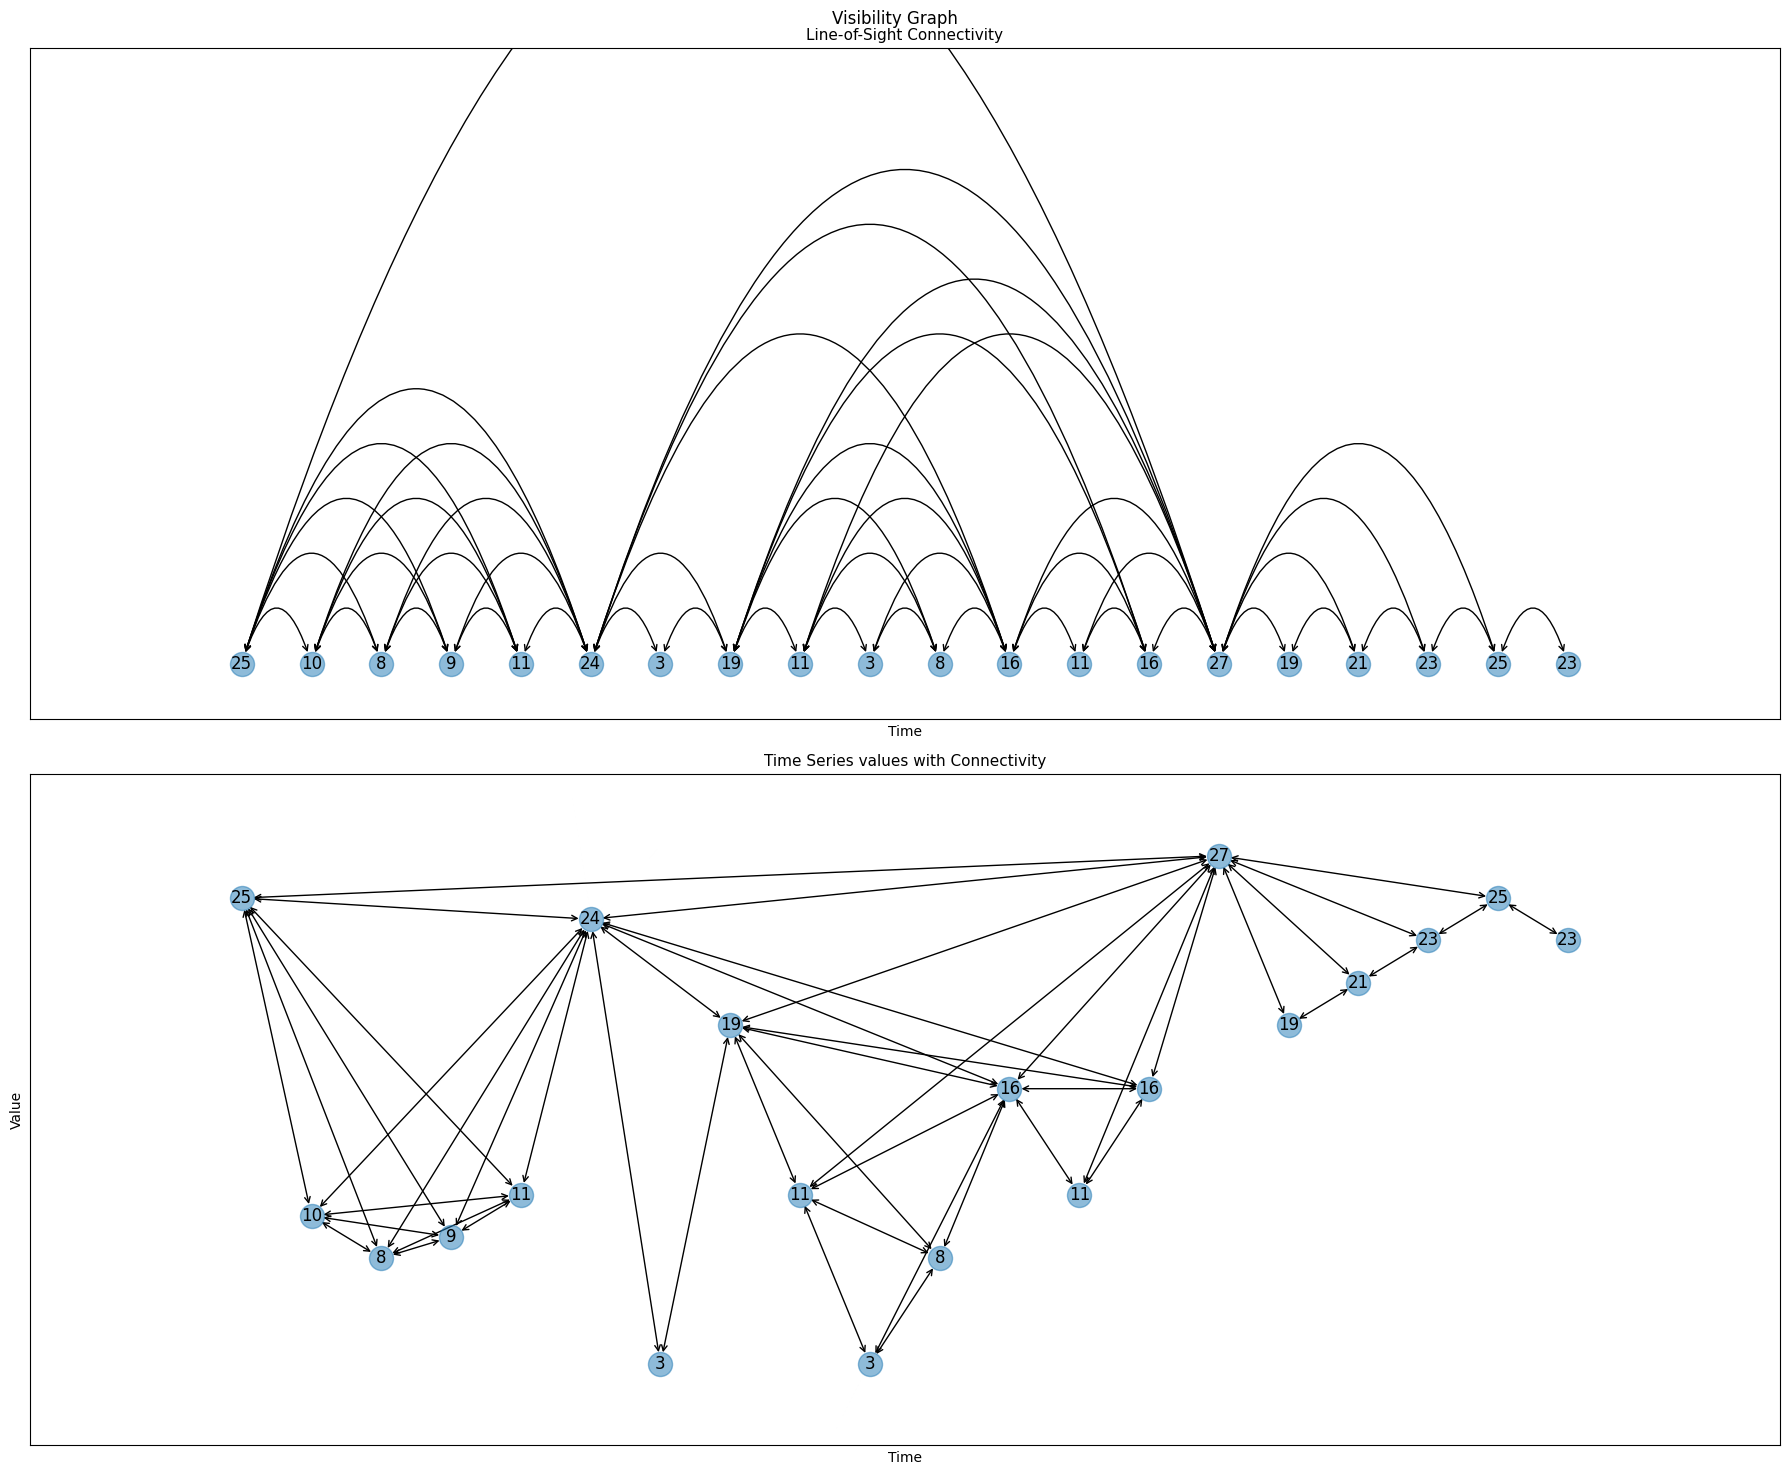

In [6]:
G = nx.visibility_graph(ts)

labels = nx.get_node_attributes(G, "value")

fig, all_axes = plt.subplots(2, 1, num="Visibility Graph", figsize=(18, 15))
axs = all_axes.flat

layouts_params = {
    # a layout emphasizing the line-of-sight connectivity
    "Line-of-Sight Connectivity": {
        "pos": {x: (x, 0) for x in range(len(ts))},
        "connectionstyle": "arc3,rad=-1.57079632679",
    },
    # a layout showcasing the time series values
    "Time Series values with Connectivity": {
        "pos": {i: (i, v) for i, v in enumerate(ts)}
    },
}

for i, (name, params) in enumerate(layouts_params.items()):
    axs[i].title.set_text(name)
    axs[i].title.set_size(11)
    axs[i].set_xlabel("Time", size=10)
    axs[i].margins(0.10)
    nx.draw_networkx_nodes(G, params.get("pos"), ax=axs[i], alpha=0.5)
    nx.draw_networkx_labels(G, params.get("pos"), ax=axs[i], labels=labels)
    nx.draw_networkx_edges(
        G, **params, ax=axs[i], arrows=True, arrowstyle="<->", arrowsize=10
    )

axs[1].set_ylabel("Value", size=10)

fig.suptitle("Visibility Graph")
fig.tight_layout()
plt.show()

In [7]:
np.mean(list(nx.betweenness_centrality(G).values()))

np.float64(0.06228070175438598)

In [8]:
nx.betweenness_centrality(G)

{0: 0.08187134502923976,
 1: 0.0,
 2: 0.0,
 3: 0.0,
 4: 0.0,
 5: 0.2923001949317739,
 6: 0.0,
 7: 0.08372319688109159,
 8: 0.03576998050682262,
 9: 0.0,
 10: 0.0034113060428849896,
 11: 0.12904483430799224,
 12: 0.0,
 13: 0.011695906432748537,
 14: 0.49376218323586746,
 15: 0.0,
 16: 0.0029239766081871343,
 17: 0.005847953216374269,
 18: 0.10526315789473684,
 19: 0.0}

In [9]:
#### image version
#### https://core.ac.uk/download/pdf/201006092.pdf.
#### Iacovacci, J., & Lacasa, L. (2019). Visibility graphs for image processing. 
#### IEEE transactions on pattern analysis and machine intelligence, 42(4), 974-987.

In [10]:
import numpy as np
import cv2
from numpy.lib.stride_tricks import as_strided

def _extract_patches_2d(img: np.ndarray, k: int):
    """Devuelve una vista con forma (H-k+1, W-k+1, k, k) sin copiar."""
    H, W = img.shape
    out_shape = (H - k + 1, W - k + 1, k, k)
    s0, s1 = img.strides
    out_strides = (s0, s1, s0, s1)
    return as_strided(img, shape=out_shape, strides=out_strides, writeable=False)

def _visibility_line(lines: np.ndarray):
    """
    lines: (..., k) valores
    Regresa booleanos (...,) para el predicado:
       x1 < x0  AND  x2>x1 AND x3>x2 ... (estrictamente creciente desde x1)
    """
    k = lines.shape[-1]
    if k < 3:
        raise ValueError("order (k) debe ser >= 3.")
    # x1 < x0
    start_ok = lines[..., 1] < lines[..., 0]
    # x2>x1, x3>x2, ...
    if k == 3:
        grow_ok = lines[..., 2] > lines[..., 1]
    else:
        grow_ok = np.all(lines[..., 2:] > lines[..., 1:-1], axis=-1)
    return start_ok & grow_ok

def patch_profile_visibility_vectorized(img: np.ndarray, order: int = 3):
    """
    Perfil de visibilidad por parches k×k (k=order) vectorizado.

    Parámetros
    ----------
    img   : np.ndarray (H, W), escala de grises
    order : int >= 3, tamaño del parche k

    Retorna
    -------
    Z     : np.ndarray (2**T + 1,), histograma (índice 0 sin uso)
    Lmap  : np.ndarray (H-k+1, W-k+1), etiqueta en [1, 2**T]
    """
    if img.ndim != 2:
        raise ValueError("img debe ser 2D (escala de grises).")
    k = int(order)
    if k < 3:
        raise ValueError("order debe ser >= 3.")
    H, W = img.shape
    if H < k or W < k:
        raise ValueError(f"La imagen debe ser al menos de {k}×{k} píxeles.")

    I = img.astype(np.int64, copy=False)
    patches = _extract_patches_2d(I, k)  # (H', W', k, k)
    Hp, Wp = patches.shape[:2]

    # --- Construir todas las líneas a evaluar (en bloque) ---
    # Filas: k líneas por parche → shape (H', W', k, k)
    row_lines = patches  # cada ...[r, :] es una fila
    # Columnas: k líneas por parche → (H', W', k, k)
    col_lines = np.swapaxes(patches, -1, -2)  # para que ...[c, :] sea la columna c
    # Diagonal principal: (..., k)
    idx = np.arange(k)
    diag_main = patches[..., idx, idx]
    # Diagonal secundaria: (..., k)
    diag_anti = patches[..., idx, k - 1 - idx]

    # --- Evaluar el predicado en bloque ---
    # Para filas/columnas queremos un booleano por fila/columna.
    row_ok = _visibility_line(row_lines)            # (H', W', k)
    col_ok = _visibility_line(col_lines)            # (H', W', k)
    d1_ok  = _visibility_line(diag_main)            # (H', W')
    d2_ok  = _visibility_line(diag_anti)            # (H', W')

    # --- Empaquetar bits en el orden: filas(0..k-1), columnas(0..k-1), diag_main, diag_anti ---
    T = 2 * k + 2
    Vbits = np.zeros((Hp, Wp, T), dtype=np.uint8)
    Vbits[:, :, :k] = row_ok
    Vbits[:, :, k:2*k] = col_ok
    Vbits[:, :, 2*k] = d1_ok
    Vbits[:, :, 2*k + 1] = d2_ok

    # Convertir bits → entero (bit más significativo = test 0)
    # L = 1 + sum V[i] * 2**(T-1-i)
    powers = (1 << np.arange(T-1, -1, -1, dtype=np.int64))  # (T,)
    labels_0based = (Vbits.astype(np.int64) * powers).sum(axis=-1)  # (H', W')
    Lmap = (labels_0based + 1).astype(np.int32)

    # Histograma (índice 0 sin uso para mantener compatibilidad con pseudocódigo)
    Z = np.bincount(Lmap.ravel(), minlength=(1 << T) + 1)
    # Aseguramos longitud exacta
    if Z.size < (1 << T) + 1:
        Z = np.pad(Z, (0, (1 << T) + 1 - Z.size), constant_values=0)

    return Z, Lmap

In [11]:
## Ejemplo sencillo....

In [12]:
import numpy as np
from numpy.lib.stride_tricks import as_strided

def _extract_patches_2d(img: np.ndarray, k: int):
    H, W = img.shape
    out_shape = (H - k + 1, W - k + 1, k, k)
    s0, s1 = img.strides
    out_strides = (s0, s1, s0, s1)
    return as_strided(img, shape=out_shape, strides=out_strides, writeable=False)

def _visibility_line(lines: np.ndarray):
    k = lines.shape[-1]
    if k < 3:
        raise ValueError("order (k) debe ser >= 3.")
    start_ok = lines[..., 1] < lines[..., 0]
    if k == 3:
        grow_ok = lines[..., 2] > lines[..., 1]
    else:
        grow_ok = np.all(lines[..., 2:] > lines[..., 1:-1], axis=-1)
    return start_ok & grow_ok

def patch_profile_visibility_vectorized(img: np.ndarray, order: int = 3):
    k = int(order)
    if img.ndim != 2:
        raise ValueError("img debe ser 2D (escala de grises).")
    if k < 3:
        raise ValueError("order debe ser >= 3.")
    H, W = img.shape
    if H < k or W < k:
        raise ValueError(f"La imagen debe ser al menos de {k}×{k} píxeles.")
    I = img.astype(np.int64, copy=False)
    patches = _extract_patches_2d(I, k)  # (H', W', k, k)
    Hp, Wp = patches.shape[:2]

    row_lines = patches
    col_lines = np.swapaxes(patches, -1, -2)
    idx = np.arange(k)
    diag_main = patches[..., idx, idx]
    diag_anti = patches[..., idx, k - 1 - idx]

    row_ok = _visibility_line(row_lines)
    col_ok = _visibility_line(col_lines)
    d1_ok = _visibility_line(diag_main)
    d2_ok = _visibility_line(diag_anti)

    T = 2 * k + 2
    Vbits = np.zeros((Hp, Wp, T), dtype=np.uint8)
    Vbits[:, :, :k] = row_ok
    Vbits[:, :, k:2*k] = col_ok
    Vbits[:, :, 2*k] = d1_ok
    Vbits[:, :, 2*k + 1] = d2_ok

    powers = (1 << np.arange(T-1, -1, -1, dtype=np.int64))
    labels_0based = (Vbits.astype(np.int64) * powers).sum(axis=-1)
    Lmap = (labels_0based + 1).astype(np.int32)

    Z = np.bincount(Lmap.ravel(), minlength=(1 << T) + 1)
    if Z.size < (1 << T) + 1:
        Z = np.pad(Z, (0, (1 << T) + 1 - Z.size), constant_values=0)

    return Z, Lmap, Vbits

# Ejemplo pequeño para inspección
img_small = np.array([
    [10,  5,  9,  7],
    [ 8,  3,  4, 11],
    [ 6,  1,  2, 12],
    [ 7,  2,  8, 13]
], dtype=np.uint8)

Z, Lmap, Vbits = patch_profile_visibility_vectorized(img_small, order=3)

Z_sum = Z.sum()
most_freq_label = np.argmax(Z[1:]) + 1
most_freq_count = Z[most_freq_label]

(Z_sum, most_freq_label, most_freq_count, Lmap, Vbits)


(np.int64(4),
 np.int64(3),
 np.int64(1),
 array([[226,   3],
        [256,  27]], dtype=int32),
 array([[[1, 1, 1, 0, 0, 0, 0, 1],
         [0, 0, 0, 0, 0, 0, 1, 0]],
 
        [[1, 1, 1, 1, 1, 1, 1, 1],
         [0, 0, 0, 1, 1, 0, 1, 0]]], dtype=uint8))

**Vbits — bits de visibilidad para cada parche**

**Orden de bits:**
- **Filas:** \(V(1), V(2), V(3)\)
- **Columnas:** \(V(4), V(5), V(6)\)
- **Diagonal principal:** \(V(7)\)
- **Diagonal secundaria:** \(V(8)\)

---

**Parche (0,0) — etiqueta 226**  
`V = [1, 1, 1, 0, 0, 0, 0, 1]`

Esto significa:
- Fila 1: visible ✔️
- Fila 2: visible ✔️
- Fila 3: visible ✔️
- Columna 1: ✖️
- Columna 2: ✖️
- Columna 3: ✖️
- Diag. principal: ✖️
- Diag. secundaria: ✔️

---

**Parche (0,1) — etiqueta 3**  
`V = [0, 0, 0, 0, 0, 0, 1, 0]`  
Solo la diagonal principal cumple.

---

**Parche (1,0) — etiqueta 256**  
`V = [1, 1, 1, 1, 1, 1, 1, 1]`  
Todos los tests cumplen.

---

**Parche (1,1) — etiqueta 27**  
`V = [0, 0, 0, 1, 1, 0, 1, 0]`  
Columnas 1 y 2 visibles, diagonal principal visible.


## Ejemplo completo

In [13]:
import numpy as np
import cv2
from numpy.lib.stride_tricks import as_strided

def _extract_patches_2d(img: np.ndarray, k: int):
    """Devuelve una vista con forma (H-k+1, W-k+1, k, k) sin copiar."""
    H, W = img.shape
    out_shape = (H - k + 1, W - k + 1, k, k)
    s0, s1 = img.strides
    out_strides = (s0, s1, s0, s1)
    return as_strided(img, shape=out_shape, strides=out_strides, writeable=False)

def _visibility_line(lines: np.ndarray):
    """
    lines: (..., k) valores
    Regresa booleanos (...,) para el predicado:
       x1 < x0  AND  x2>x1 AND x3>x2 ... (estrictamente creciente desde x1)
    """
    k = lines.shape[-1]
    if k < 3:
        raise ValueError("order (k) debe ser >= 3.")
    # x1 < x0
    start_ok = lines[..., 1] < lines[..., 0]
    # x2>x1, x3>x2, ...
    if k == 3:
        grow_ok = lines[..., 2] > lines[..., 1]
    else:
        grow_ok = np.all(lines[..., 2:] > lines[..., 1:-1], axis=-1)
    return start_ok & grow_ok

def patch_profile_visibility_vectorized(img: np.ndarray, order: int = 3):
    """
    Perfil de visibilidad por parches k×k (k=order) vectorizado.

    Parámetros
    ----------
    img   : np.ndarray (H, W), escala de grises
    order : int >= 3, tamaño del parche k

    Retorna
    -------
    Z     : np.ndarray (2**T + 1,), histograma (índice 0 sin uso)
    Lmap  : np.ndarray (H-k+1, W-k+1), etiqueta en [1, 2**T]
    """
    if img.ndim != 2:
        raise ValueError("img debe ser 2D (escala de grises).")
    k = int(order)
    if k < 3:
        raise ValueError("order debe ser >= 3.")
    H, W = img.shape
    if H < k or W < k:
        raise ValueError(f"La imagen debe ser al menos de {k}×{k} píxeles.")

    I = img.astype(np.int64, copy=False)
    patches = _extract_patches_2d(I, k)  # (H', W', k, k)
    Hp, Wp = patches.shape[:2]

    # --- Construir todas las líneas a evaluar (en bloque) ---
    # Filas: k líneas por parche → shape (H', W', k, k)
    row_lines = patches  # cada ...[r, :] es una fila
    # Columnas: k líneas por parche → (H', W', k, k)
    col_lines = np.swapaxes(patches, -1, -2)  # para que ...[c, :] sea la columna c
    # Diagonal principal: (..., k)
    idx = np.arange(k)
    diag_main = patches[..., idx, idx]
    # Diagonal secundaria: (..., k)
    diag_anti = patches[..., idx, k - 1 - idx]

    # --- Evaluar el predicado en bloque ---
    # Para filas/columnas queremos un booleano por fila/columna.
    row_ok = _visibility_line(row_lines)            # (H', W', k)
    col_ok = _visibility_line(col_lines)            # (H', W', k)
    d1_ok  = _visibility_line(diag_main)            # (H', W')
    d2_ok  = _visibility_line(diag_anti)            # (H', W')

    # --- Empaquetar bits en el orden: filas(0..k-1), columnas(0..k-1), diag_main, diag_anti ---
    T = 2 * k + 2
    Vbits = np.zeros((Hp, Wp, T), dtype=np.uint8)
    Vbits[:, :, :k] = row_ok
    Vbits[:, :, k:2*k] = col_ok
    Vbits[:, :, 2*k] = d1_ok
    Vbits[:, :, 2*k + 1] = d2_ok

    # Convertir bits → entero (bit más significativo = test 0)
    # L = 1 + sum V[i] * 2**(T-1-i)
    powers = (1 << np.arange(T-1, -1, -1, dtype=np.int64))  # (T,)
    labels_0based = (Vbits.astype(np.int64) * powers).sum(axis=-1)  # (H', W')
    Lmap = (labels_0based + 1).astype(np.int32)

    # Histograma (índice 0 sin uso para mantener compatibilidad con pseudocódigo)
    Z = np.bincount(Lmap.ravel(), minlength=(1 << T) + 1)
    # Aseguramos longitud exacta
    if Z.size < (1 << T) + 1:
        Z = np.pad(Z, (0, (1 << T) + 1 - Z.size), constant_values=0)

    return Z, Lmap

In [14]:
# -----------------------
# Ejemplo rápido de uso:
if __name__ == "__main__":
    rng = np.random.default_rng(1)
    #img = cv2.imread("Lenna_(test_image).png")
    img = cv2.imread("Lenna_(test_image).png")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)#rng.integers(0, 256, size=(1024, 1024), dtype=np.uint8)

    # k=3 (mismo caso del pseudocódigo): T=8 → 256 etiquetas
    Z3, L3 = patch_profile_visibility_vectorized(img, order=3)
    print("Parche 3×3 → etiquetas:", L3.shape, "hist. len:", len(Z3))

    # k=4: T=10 → 1024 etiquetas
    Z4, L4 = patch_profile_visibility_vectorized(img, order=4)
    print("Parche 4×4 → etiquetas:", L4.shape, "hist. len:", len(Z4))

    # k=5: T=12 → 4096 etiquetas
    Z5, L5 = patch_profile_visibility_vectorized(img, order=5)
    print("Parche 5×5 → etiquetas:", L5.shape, "hist. len:", len(Z5))

Parche 3×3 → etiquetas: (510, 510) hist. len: 257
Parche 4×4 → etiquetas: (509, 509) hist. len: 1025
Parche 5×5 → etiquetas: (508, 508) hist. len: 4097


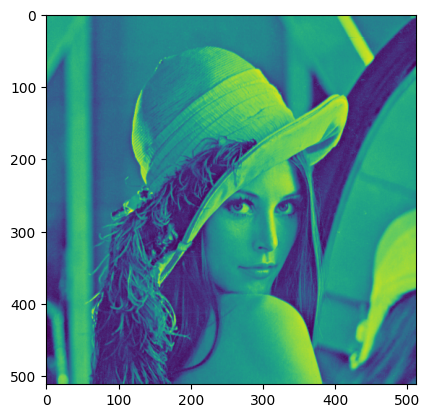

In [15]:
plt.imshow(img)

In [16]:
Z3

array([    0, 76814,  3996,  2903,     0, 14410,  1030,  1095,     0,
        8339,  1730,  1701,     0,  3053,  1033,  1176,   806, 14352,
         971,  1026,     0,  3086,   176,   192,     0,  3131,  1148,
        1190,   901,   970,   402,   401,   755, 10252,  1398,  1206,
           0,  3541,  1037,   723,   490,   111,   205,   177,     0,
          23,   174,    93,   275,  3065,   585,   951,   408,   842,
         267,   230,   318,    25,    82,   156,   262,     6,    46,
          38,   262,  4692,  1536,  1475,     0,   182,   137,   169,
           0,  2374,  2477,  2675,  3220,   191,   271,   452,   959,
         162,   128,   168,     0,     0,     0,     0,     0,   126,
         292,   331,   976,     0,     0,     0,   270,  1938,  1342,
        1218,  1199,    61,   227,    98,   354,    94,   433,   375,
        1249,     0,   177,     0,   527,    38,    73,   188,   293,
           0,     0,     0,    81,     0,     0,   145,   508,     0,
           0,     0,

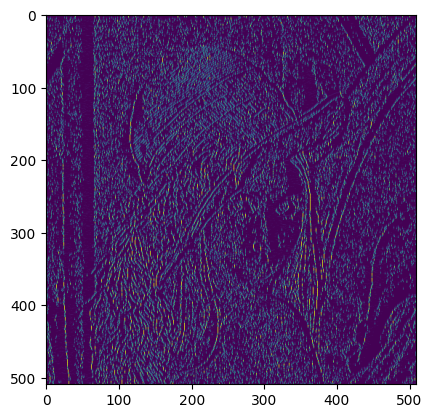

In [17]:
plt.imshow(L4)

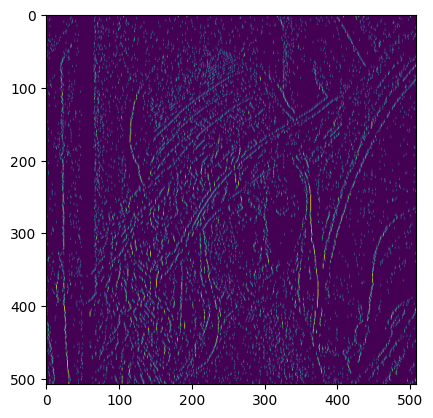

In [18]:
plt.imshow(L5)

In [19]:
len(img), len(Z3), len(L3)

(512, 257, 510)

In [20]:
Z3

array([    0, 76814,  3996,  2903,     0, 14410,  1030,  1095,     0,
        8339,  1730,  1701,     0,  3053,  1033,  1176,   806, 14352,
         971,  1026,     0,  3086,   176,   192,     0,  3131,  1148,
        1190,   901,   970,   402,   401,   755, 10252,  1398,  1206,
           0,  3541,  1037,   723,   490,   111,   205,   177,     0,
          23,   174,    93,   275,  3065,   585,   951,   408,   842,
         267,   230,   318,    25,    82,   156,   262,     6,    46,
          38,   262,  4692,  1536,  1475,     0,   182,   137,   169,
           0,  2374,  2477,  2675,  3220,   191,   271,   452,   959,
         162,   128,   168,     0,     0,     0,     0,     0,   126,
         292,   331,   976,     0,     0,     0,   270,  1938,  1342,
        1218,  1199,    61,   227,    98,   354,    94,   433,   375,
        1249,     0,   177,     0,   527,    38,    73,   188,   293,
           0,     0,     0,    81,     0,     0,   145,   508,     0,
           0,     0,